# Job 51668331 — is the ~2M parameter floor the TASK's, or only `L=12`'s?

Stage J moved the standing minimum to attention-only `L=16 d192` — 2,504,890
trainable at `rho_50` 0.580, 3/3 seeds — and STATUS read the frontier as *"a
floor near 2M parameters on this task, and everything above it is flat"*.

That reading has a hole in it, and stage K is the hole. **Every rung below 2M on
record is an `L=12` rung.** The width ladder that measured the floor was run at
one depth:

| rung | architecture | trainable | `rho_50` |
|---|---|---|---|
| H1 | attention-only `L=12 d128` | 879,418 | CENSORED |
| I1 | attention-only `L=12 d160` | 1,345,018 | 0.773 |
| H2 | attention-only `L=12 d192` | 1,908,922 | 0.754 |
| J1 | attention-only `L=12 d224` | 2,571,130 | 0.579 |
| E2 | attention-only `L=12 d256` | 3,331,642 | 0.605 |

And at `d192` the one depth step that has been measured — `L=12` → `L=16`, H2 →
J2 — moved `rho_50` **0.754 → 0.580** and carried the rung across the 0.740 free
line. If depth can buy back that much at `d192`, the obvious question is whether
it buys back the same thing at `d160`, where `L=12` sat at 0.773, barely inside
the barrier band and 0.033 above the free line.

Stage K runs the same width ladder one depth up, three seeds each, **one
`d_model` knob from J2**:

* **KA** = attention-only `L=16 d160`, 1,759,738 trainable predicted
* **KB** = attention-only `L=16 d128`, 1,145,658 trainable predicted

**The registered predictions, from `scripts/stagek_score.py` (`262b581`),
committed while `51668331` was still training and before any K cell had an eval
on disk:**

* **K0** — KA lands FREE, point estimate `rho_50` **0.599** (= I1's 0.773 minus
  the measured depth step 0.174, carried across unchanged), band **[0.55, 0.70]**.
  The robust binary call is the FREE one; the point estimate is the fragile one,
  and it is written down so that a miss cannot be re-read afterwards as a hit.
* **K1** — KB CENSORS. If it censors having escaped the 1.64 plateau on ≥2 seeds
  that is an ARCHITECTURE statement; if it never escapes it is a TRAINABILITY
  statement and says nothing about shape. **K1 gates the architecture reading of
  KB** the way F1 gates F0.
* **K2** — the standing-minimum rule, unchanged since H3: a rung replaces the
  minimum only if **3 of 3** seeds cross AND median `rho_50` ≤ 0.740. Two of
  three is never enough (finding 51). The tie-break, named in advance, is the
  **smaller parameter count**.
* **K3** — `rho_50` before and after on the same pooled `s*` eval.
* **K4** — what the stage leaves open.

Section 2 prints which branch the data landed in. Section 8 gives `rho_50`
before and after against the previous best on the same eval. This notebook runs
the scorer; it does not restate its conclusions in its own words.

In [1]:
import json, os, subprocess, sys
sys.path.insert(0, "/home/users/hshunt/spin_gnn")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

REPO = "/home/users/hshunt/spin_gnn"
BOOT = 2000          # the programme's scoring default; CIs here match the scorers'
SEEDS = (0, 1, 2)    # both rungs are 3 seeds

from scripts.minarch_analysis import SCAN_DIRS, SCAN_E, SCAN_G, SCAN_H, SCAN_I, SCAN_J
from scripts.stagec_score import HUB, PLATEAU, S_RHO50, S_MEAN, escapes, rho_txt, rung, summarize
from scripts.stagek_score import (DEPTH_STEP_AT_D192, E2, FREE, H1, H2, HUB_RHO50,
                                  HUB_TRAINABLE, I1, I1_RHO50, J1, J2, KA, KB, LOO_BAR,
                                  PRED_KA_HI, PRED_KA_LO, PRED_KA_POINT,
                                  PREDICTED_TRAINABLE, SCAN_K, STANDING)
from notebooks.make_stagek_deck import (FULL_L12, KA_TITLE, LADDER_12, LADDER_16, acc_of,
                                        collect, ladder, new_minimum, pair, qualifies,
                                        sufficiency, verdict_ka, verdict_kb)

# SCAN_K is read here and HAS to be -- it is the subject. It stays out of
# SCAN_DIRS, and so out of the pooled s*, because its rungs would otherwise
# enter the yardstick that stages A-F were already scored against. s* is quoted
# frozen below and never recomputed.
DIRS = SCAN_DIRS + [SCAN_E, SCAN_G, SCAN_H, SCAN_I, SCAN_J, SCAN_K]

COMMIT = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=REPO,
                        capture_output=True, text=True).stdout.strip()
print("git commit        ", COMMIT)
print("branch            ", subprocess.run(["git", "rev-parse", "--abbrev-ref", "HEAD"],
                                           cwd=REPO, capture_output=True,
                                           text=True).stdout.strip())
print("scorer registered ", "262b581, while 51668331 was still training")
print("deck registered   ", "0662d8b, same -- no K cell had an eval on disk")
print("bootstrap draws   ", BOOT)
print("seeds per rung    ", SEEDS)
print("frozen yardstick  ", f"s* = {S_RHO50} in rho_50, {S_MEAN} in mean_solve")
print("plateau           ", f"train NLL {PLATEAU} (finding 44, an N=48 number)")
print("free line         ", f"rho_50 <= {FREE:.3f} (hub {HUB_RHO50} + s*)")
print("depth step used   ", f"{DEPTH_STEP_AT_D192:.3f} at d192 (H2 0.754 -> J2 0.580)")
print("K0 prediction     ", f"{PRED_KA_POINT:.3f} in "
                            f"[{PRED_KA_LO:.2f}, {PRED_KA_HI:.2f}], and FREE")
print("sufficiency bar   ", f"leave-one-out RMS {LOO_BAR}")
print("scan dirs         ", len(DIRS), "dirs; the subject is", os.path.basename(SCAN_K))

git commit         5a1f4f6
branch             sudoku-dd
scorer registered  262b581, while 51668331 was still training
deck registered    0662d8b, same -- no K cell had an eval on disk
bootstrap draws    2000
seeds per rung     (0, 1, 2)
frozen yardstick   s* = 0.1484 in rho_50, 0.2918 in mean_solve
plateau            train NLL 1.64 (finding 44, an N=48 number)
free line          rho_50 <= 0.740 (hub 0.592 + s*)
depth step used    0.174 at d192 (H2 0.754 -> J2 0.580)
K0 prediction      0.599 in [0.55, 0.70], and FREE
sufficiency bar    leave-one-out RMS 0.0423
scan dirs          10 dirs; the subject is sudoku_n48_minarch_K_2026-11-09


## 2. The headline, selected by the branch the data fell in

The seven KA branches and the three KB branches below were named in
`stagek_score.py` and in `make_stagek_deck.py` before the run closed. The cell
picks one; it does not compose a sentence. The same `verdict_ka` /
`verdict_kb` / `new_minimum` helpers drive the slides, so the deck and this page
cannot disagree about which outcome happened.

In [2]:
cells, raw = collect(DIRS, BOOT)
p = pair(cells)
l12, l16 = ladder(cells, LADDER_12), ladder(cells, LADDER_16)
vka, vkb = verdict_ka(p["KA"]), verdict_kb(p["KB"])

print(f"{len(cells)} cells on disk | "
      + " | ".join(f"{t} {p[t]['s']['n']}/3 seeds" for t in ("KA", "KB")) + chr(10))
print("KA  attention-only L=16 d160  ->  branch", vka.upper())
print("KB  attention-only L=16 d128  ->  branch", vkb.upper())
print()
print("  " + KA_TITLE[vka])
print()
print(f"  {'rung':<30}{'rho_50':>10}{'mean_solve':>12}{'cross':>8}{'esc':>6}{'trainable':>12}")
print("  " + "-" * 78)
for t in ("KA", "KB"):
    s, r = p[t]["s"], p[t]
    nm = "d160" if t == "KA" else "d128"
    print(f"  {t + '  attention-only L=16 ' + nm:<30}{rho_txt(s):>10}"
          f"{s['mean_solve']:>12.4f}{s['n_cross']:>5}/{s['n']}{r['esc']:>4}/{s['n']}"
          f"{s['trainable']:>12,}")

print()
mv = new_minimum(p)
if mv is None:
    print(f"  K2: NEITHER rung replaces the standing minimum. It stays at "
          f"{STANDING[1]}, {STANDING[2]:,} at {STANDING[3]:.3f}.")
else:
    # Both rungs can satisfy K2, and KB is the smaller, so the pre-named
    # tie-break can hand the minimum to either one. Computed, never assumed.
    both = [t for t in ("KA", "KB") if qualifies(p[t])]
    print(f"  K2: {', '.join(both)} satisfy the rule (3/3 crossing, median <= {FREE:.3f}); "
          f"the pre-named tie-break takes the smaller.")
    print(f"      the minimum MOVES to {mv['tag']}, {mv['s']['trainable']:,} at "
          f"{mv['s']['rho50']:.3f} -- {STANDING[2] / mv['s']['trainable']:.2f}x "
          f"below {STANDING[0]}, {HUB_TRAINABLE / mv['s']['trainable']:.2f}x below the hub.")

105 cells on disk | KA 3/3 seeds | KB 3/3 seeds

KA  attention-only L=16 d160  ->  branch HIGH
KB  attention-only L=16 d128  ->  branch CROSSED

  The depth gain does not transport: the ~2M floor stands

  rung                              rho_50  mean_solve   cross   esc   trainable
  ------------------------------------------------------------------------------
  KA  attention-only L=16 d160       0.757      0.3163    3/3   3/3   1,759,738
  KB  attention-only L=16 d128       0.766      0.3168    3/3   2/3   1,145,658

  K2: NEITHER rung replaces the standing minimum. It stays at attention-only L=16 d192, 2,504,890 at 0.580.


## 3. Provenance: one knob from J2, and the budget the knob buys

Stage J had to move two fields at once to hold a budget still, and its
provenance section was a matched-budget argument. Stage K is the ordinary kind
again: **`d_model` is the only field that moves**, from J2's 192 down to 160 and
128, at a fixed `num_layers` = 16. Everything else — pool, epochs, lr and
schedule, `dim_feedforward`, `nhead`, `arch_mode`, and the `--shuffle-adj
--fall` leak-free task — is the same as J2's and the same as the `L=12` ladder's.

That matters because the comparison being made is **vertical**: KA against I1 at
the same width one depth down, and KA against J2 at the same depth one width
across. Both legs are one-knob, which is what lets the depth step measured at
`d192` be carried to `d160` as a prediction at all.

The parameter count is checked against the registered formula —
`4*d^2 + 8*d` per layer plus `630*d + 58` fixed — which the sbatch asserts
before training, so a model that built differently would have aborted rather
than produced a cell.

In [3]:
FIELDS = ("num_layers", "d_model", "dim_feedforward", "nhead", "arch_mode", "epochs",
          "lr", "lr_schedule", "batch_size", "n_train_instances", "warmup_epochs",
          "shuffle_adj", "fall", "n_nodes", "degree", "n_colors")
print(f"{'rung':<30}" + "".join(f"{f.replace('_', ' ')[:11]:>13}" for f in FIELDS[:5]))
print("-" * 95)
base = None
for t in ("KA", "KB"):
    cfg = json.load(open(os.path.join(p[t]["ms"][0]["path"], "config.json")))
    nm = "d160" if t == "KA" else "d128"
    print(f"{t + '  attention-only L=16 ' + nm:<30}"
          + "".join(f"{str(cfg.get(f)):>13}" for f in FIELDS[:5]))
    base = base or cfg

print()
print("THE ONE KNOB THAT MOVES: d_model. Everything else, per cell:")
for t in ("KA", "KB"):
    for m in p[t]["ms"]:
        a = json.load(open(os.path.join(m["path"], "config.json")))
        # solve_metrics, baseline_accuracy and n_trainable_params are written
        # back into config.json by the runner -- outputs of the cell, not inputs.
        diff = sorted(k for k in set(a) | set(base) if a.get(k) != base.get(k)
                      and k not in ("out_dir", "run_name", "seed", "d_model",
                                    "solve_metrics", "baseline_accuracy",
                                    "n_trainable_params"))
        print(f"  {t} seed {a['seed']}: fields differing besides d_model and seed: "
              f"{diff or 'NONE'}")
print()
print("held constant across all 6 cells:",
      "  ".join(f"{f}={base.get(f)}" for f in FIELDS[5:]))

print()
print("AND against J2, the rung stage K steps down from:")
j2cfg = json.load(open(os.path.join(rung(cells, J2)[0]["path"], "config.json")))
jdiff = sorted(k for k in set(j2cfg) | set(base) if j2cfg.get(k) != base.get(k)
               and k not in ("out_dir", "run_name", "seed", "d_model",
                             "solve_metrics", "baseline_accuracy", "n_trainable_params"))
print(f"  J2 vs KA/KB: fields differing besides d_model and seed: {jdiff or 'NONE'}")

print()
print("THE BUDGET -- registered formula vs what the models actually built")
print(f"  {'rung':<8}{'predicted':>12}{'observed':>12}   formula 4*d^2+8*d per layer, 630*d+58 fixed")
print("  " + "-" * 76)
for t in ("KA", "KB"):
    L, d = p[t]["key"][0], p[t]["key"][3]
    want = PREDICTED_TRAINABLE[t]
    assert want == L * (4 * d * d + 8 * d) + 630 * d + 58, "formula disagrees with registration"
    got = p[t]["s"]["trainable"]
    print(f"  {t:<8}{want:>12,}{got:>12,}   {'ok' if want == got else 'MISMATCH'}"
          f"   (registered in the sbatch)")

rung                             num layers      d model  dim feedfor        nhead    arch mode
-----------------------------------------------------------------------------------------------
KA  attention-only L=16 d160             16          160         1024            4       no_mlp
KB  attention-only L=16 d128             16          128         1024            4       no_mlp

THE ONE KNOB THAT MOVES: d_model. Everything else, per cell:
  KA seed 0: fields differing besides d_model and seed: NONE
  KA seed 1: fields differing besides d_model and seed: NONE
  KA seed 2: fields differing besides d_model and seed: NONE
  KB seed 0: fields differing besides d_model and seed: NONE
  KB seed 1: fields differing besides d_model and seed: NONE
  KB seed 2: fields differing besides d_model and seed: NONE

held constant across all 6 cells: epochs=50  lr=0.001  lr_schedule=constant  batch_size=32  n_train_instances=240000  warmup_epochs=0  shuffle_adj=True  fall=True  n_nodes=48  degree=5  n

## 4. The metrics table

`rho_50` is the realized hint density at which the solve rate crosses 0.5 on a
14-point × 400-instance leak-free grid (`--shuffle-adj --fall`), **lower is
better**, reported CENSORED when no bin crosses. `mean_solve` is the unweighted
mean over the 14 bins and never censors — it is the metric to read when a rung
censors, because "CENSORED" is one bit and `mean_solve` is the rest of them.
`spread` is the seed-to-seed range in `mean_solve`, against the frozen bar `s*`
= 0.2918 on that metric. `esc` counts seeds whose final train NLL fell below the
**1.64** plateau (finding 44) — the gate that separates "this architecture
cannot do the task" from "this cell did not train".

The whole `L=16` ladder is shown against the `L=12` ladder it is a copy of, at
the same three widths, so the depth step can be read off per width rather than
only at `d192` where it was measured.

In [4]:
print(f"  {'rung':<30}{'rho_50':>10}{'mean_solve':>12}{'spread':>9}{'cross':>8}{'esc':>6}"
      f"{'tok acc':>10}{'train NLL':>11}{'trainable':>12}")
print("  " + "-" * 108)
for nm, rows in (("L=12", l12), ("L=16", l16)):
    for r in rows:
        s, nll = r["s"], sorted(escapes(r["ms"])[1])
        print(f"  {r['tag'] + '  ' + nm + ' d' + str(r['d']):<30}{rho_txt(s):>10}"
              f"{s['mean_solve']:>12.4f}{s['spread_mean']:>9.4f}{s['n_cross']:>5}/{s['n']}"
              f"{r['esc']:>4}/{s['n']}{acc_of(r['ms']):>10.4f}"
              f"{nll[len(nll) // 2]:>11.4f}{s['trainable']:>12,}")
    print()

print("  THE DEPTH STEP, per width (L=12 rung minus the L=16 rung at the same d_model)")
print("  POSITIVE means the deeper rung is better, since lower rho_50 is better.")
print("  Only the d192 step was known before this run: it is the 0.174 that K0")
print("  carried across to d160 as a prediction.")
print(f"  {'d_model':<10}{'L=12':>12}{'L=16':>12}{'step':>10}{'in s*':>9}")
print("  " + "-" * 53)
by12 = {r["d"]: r for r in l12}
for r in l16:
    o = by12.get(r["d"])
    if o is None:
        continue
    a, b = o["s"], r["s"]
    if a["rho50_readable"] and b["rho50_readable"]:
        step = a["rho50"] - b["rho50"]
        print(f"  d{r['d']:<9}{a['rho50']:>12.3f}{b['rho50']:>12.3f}{step:>+10.3f}"
              f"{abs(step) / S_RHO50:>9.2f}")
    else:
        print(f"  d{r['d']:<9}{rho_txt(a):>12}{rho_txt(b):>12}{'n/a':>10}"
              f"{'':>9}   (one side censors; read mean_solve instead: "
              f"{a['mean_solve']:.4f} vs {b['mean_solve']:.4f})")

print()
print("  per-seed rho_50 and final train NLL, stage K only")
for t in ("KA", "KB"):
    # rung() returns the cells already ordered by seed; the seed itself lives in
    # the cell's config.json, not in the metrics dict.
    sd = [json.load(open(os.path.join(m["path"], "config.json")))["seed"] for m in p[t]["ms"]]
    per = ", ".join(f"s{i} " + (f"{m['rho50']:.3f}" if m["flag"] == "ok" else "CENSORED")
                    for i, m in zip(sd, p[t]["ms"]))
    nll = "  ".join(f"{v:.4f}{'*' if v < PLATEAU else ' '}" for v in p[t]["nll"])
    print(f"    {t}  rho_50 {per}")
    print(f"    {t}  NLL    {nll}   (* = below the {PLATEAU} plateau)")

  rung                              rho_50  mean_solve   spread   cross   esc   tok acc  train NLL   trainable
  ------------------------------------------------------------------------------------------------------------
  H1  L=12 d128                   CENSORED      0.0411   0.2729    1/3   1/3    0.4607     1.6703     879,418
  I1  L=12 d160                      0.773      0.3000   0.0164    3/3   3/3    0.4818     1.6067   1,345,018
  H2  L=12 d192                      0.754      0.3220   0.1450    3/3   3/3    0.4851     1.5632   1,908,922
  J1  L=12 d224                      0.579      0.5521   0.2970    3/3   3/3    0.4948     1.5359   2,571,130
  E2  L=12 d256                      0.605      0.5214   0.0480    3/3   3/3    0.4926     1.5372   3,331,642

  KB  L=16 d128                      0.766      0.3168   0.2252    3/3   2/3    0.4817     1.6155   1,145,658
  KA  L=16 d160                      0.757      0.3163   0.2136    3/3   3/3    0.4858     1.5550   1,759,738
  J2  L

## 5. The registered scorer, run verbatim

`scripts/stagek_score.py` was committed (`262b581`) while `51668331` was still
training, before any of the six cells had an eval on disk, so no verdict here
was chosen after seeing a number. It is run as a subprocess so the words in this
notebook and on the slides can be checked against the words the scorer prints.

Two controls in it are worth naming. **K0 is registered in two strengths** — a
point estimate at 0.599 and a robust binary FREE call — and the binary one is
the claim; writing both down is what stops a point miss from being re-read
afterwards as "the band was the real prediction". **K1's gate was named before
KB ran**: a censored KB only becomes an architecture statement if ≥2 seeds
escaped the plateau, and otherwise it is a trainability statement that says
nothing about shape at all.

In [5]:
r = subprocess.run([sys.executable, "-m", "scripts.stagek_score"], cwd=REPO,
                   capture_output=True, text=True)
print("=" * 100)
print("$ python3 -m scripts.stagek_score")
print("=" * 100)
print(r.stdout)
if r.returncode != 0:
    print("STDERR:", r.stderr[-2000:])

$ python3 -m scripts.stagek_score
STAGE K: does depth buy back width BELOW the standing minimum?
  99 cells read; TWO rungs, the L=12 width ladder one depth up
  frozen bar s* = 0.1484 rho_50 / 0.2918 mean_solve, NOT recomputed
  registered: KA in [0.55, 0.70] and FREE; KB CENSORS

FROZEN-LITERAL CONTROL (the L=12 ladder and J2, re-read from disk):
  H1 matches the frozen literals
  I1 matches the frozen literals
  H2 matches the frozen literals
  J1 matches the frozen literals
  J2 matches the frozen literals
  E2 matches the frozen literals

=== KA -- no_mlp L=16 d160, the rung that tests the floor ===
  3/3 seeds on disk, 3/3 crossed 0.5
  rho_50 median     0.757   (standing minimum 0.580, I1 0.773, H2 0.754, free at or below 0.74)
  mean_solve       0.3163   [spread 0.2136]
  trainable 1,759,738   (header arithmetic 1,759,738)
  plateau escapes 3/3   final train NLL 1.5444/1.5550/1.5992

=== KB -- no_mlp L=16 d128, the rung that should break ===
  3/3 seeds on disk, 3/3 crossed 0.5

## 6. The figures, as they appear on the slides

Drawn by importing the deck module, so the notebook and the PDF cannot drift.

The first is the stage in one panel: the `L=12` width ladder (H1/I1/H2/J1/E2)
and the `L=16` one (KB/KA/J2) on one `d_model` axis, with the `L=16` training
curves against the 1.64 plateau beside them. **If the two curves are parallel,
depth and width are separable knobs down here and the floor moves down with
depth; if they converge, the ~2M floor is the task's and not `L=12`'s.** That
is the whole question in one picture.

The second is the size–quality frontier: every attention-only rung this
programme has run at N=48, against the two complete-model anchors, on a log
parameter axis.

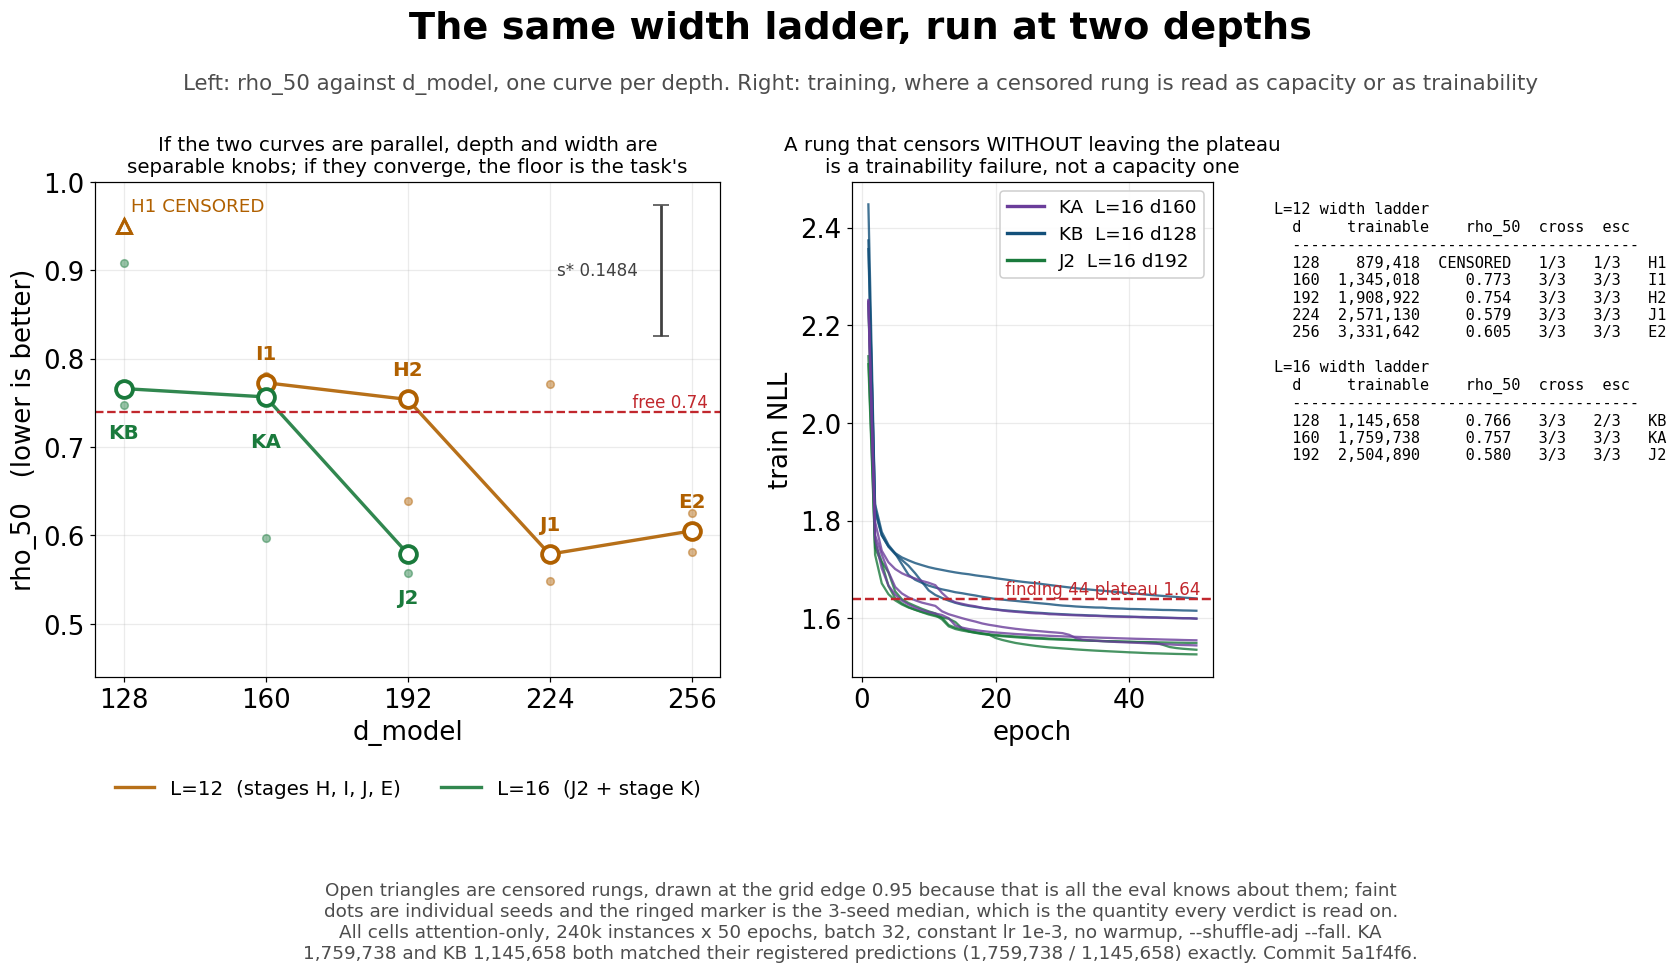

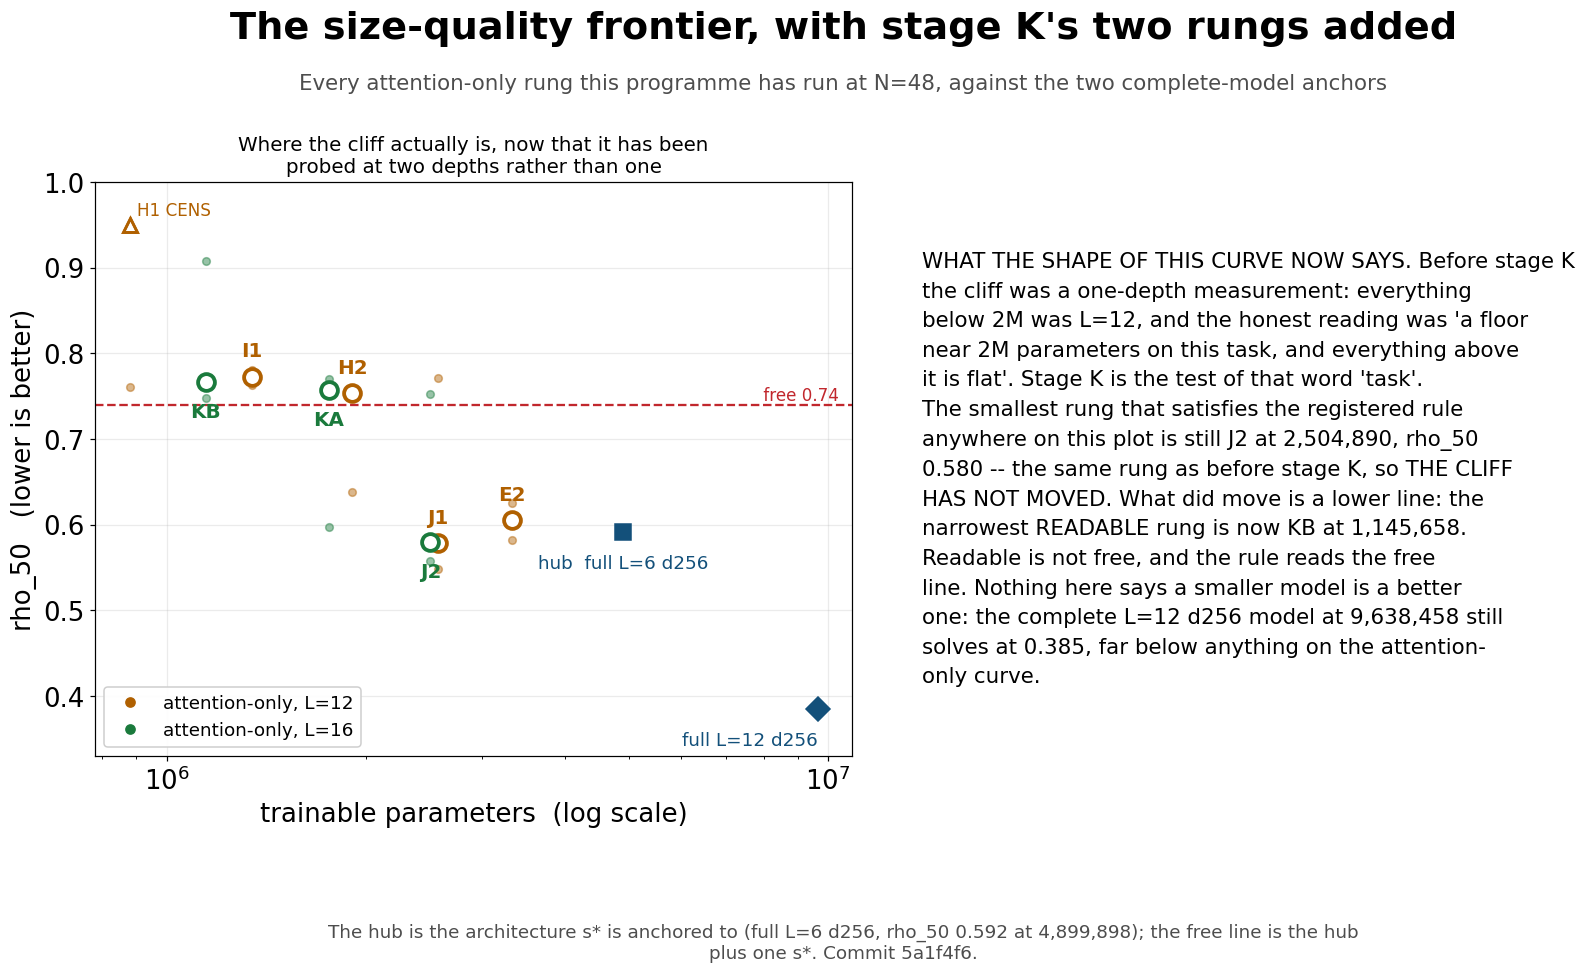

In [6]:
from notebooks.make_stagek_deck import page_frontier, page_ladders
from notebooks.deck_utils import set_style
from scripts.stagec_score import rung as _rung

set_style()
anchors = {"hub": dict(s=summarize(_rung(cells, HUB))),
           "best": dict(s=summarize(_rung(cells, FULL_L12)))}


class Keep:
    # A PdfAndPng stand-in that keeps the figure open for the notebook.
    def savefig(self, fig):
        pass


page_ladders(Keep(), l12, l16, p, COMMIT)
page_frontier(Keep(), l12, l16, anchors, COMMIT)

## 7. Does token accuracy still explain a DEPTH change at narrow width?

The programme's standing result is that a cell's mean solve rate is predicted by
its validation token accuracy alone, through a curve fitted on the **depth
ladder only** (full-width, 4-head, unmodified transformers at `L=1..12`). Stage
J was the first test of it at a changed shape and it held on J2's rung; stage K
is the first test at `L=16` and NARROW, which is the corner of the grid where a
deduction-specific failure mode would most plausibly live.

The bar is the depth ladder's own leave-one-out residual, `LOO_BAR` = 0.0423:
anything smaller is what a reference cell's own distance from the curve looks
like. Only **well-determined** cells count — ones bracketed by depth cells closer
together than the bar — and among those, the **discriminating** ones are those
the curve sends above a solve rate of 0.10, where landing on the curve is a real
constraint rather than two numbers agreeing near zero. A rung that censors can
still be well-determined: that is the interesting case, because it would mean
the curve predicted the failure from token accuracy alone.

This is a CORRELATIONAL result about this grid's range. It does not say the
architectures are the same model; it says no cut tried so far has opened a
second, deduction-specific way to fail.

In [7]:
r = subprocess.run([sys.executable, "-m", "scripts.acc_vs_solve", "--scan-dir"] + DIRS,
                   cwd=REPO, capture_output=True, text=True)
tail = r.stdout.strip().split(chr(10))
keep = [l for l in tail if l.strip().startswith(">>>") or "Worst miss" in l
        or "DISCRIMINATING --" in l or "mean residual" in l
        or l.strip().startswith("RMS") or "DETERMINED --" in l]
print(chr(10).join(keep))
print()
suf = sufficiency(DIRS)
print(f"recomputed in-process: {suf['n_exp']}/{suf['n_rungs']} well-determined held-out rungs "
      f"({suf['n_cells']} cells) on the curve,")
print(f"  {suf['n_sharp']} discriminating, worst miss {suf['worst']:.4f} against the "
      f"leave-one-out bar {suf['bar']:.4f}")
print(f"  before stage K this was 22/22 over 47 cells, worst 0.0222")
print()
print("  the two new rungs:")
for tag, k in (("KA", KA), ("KB", KB)):
    if k in suf["means"]:
        m = suf["means"][k]
        print(f"    {tag}  mean residual {m:+.4f}   "
              f"{'EXPLAINED by token accuracy' if abs(m) <= suf['bar'] else 'OFF THE CURVE'}")
    else:
        print(f"    {tag}  NOT well-determined -- it lands in a stretch of the depth ladder")
        print(f"        with no nearby cells to bracket it, so it does NOT count toward")
        print(f"        the {suf['n_exp']}. Agreement there is consistency, not evidence.")

  RMS 0.0423, max |residual| 0.1232 over 21 depth cells
=== per rung, mean residual against the bar 0.0423 ===
  -- WELL-DETERMINED -- bracketed by depth cells closer together than the bar, so these rows carry the result
     L=16 h=4 no_mlp d128       n=2  mean residual +0.0096   EXPLAINED by token accuracy
     L=12 h=4 no_mlp d192       n=2  mean residual +0.0076   EXPLAINED by token accuracy
     L=16 h=4 no_mlp d192       n=1  mean residual +0.0062   EXPLAINED by token accuracy
     L=6  h=4 no_mlp d384       n=2  mean residual +0.0061   EXPLAINED by token accuracy
     L=12 h=4 no_mlp d128       n=2  mean residual +0.0057   EXPLAINED by token accuracy
     L=6  h=4 linear            n=3  mean residual +0.0036   EXPLAINED by token accuracy
     L=6  h=4 full ff256        n=1  mean residual +0.0036   EXPLAINED by token accuracy
     L=12 h=4 no_mlp            n=1  mean residual +0.0004   EXPLAINED by token accuracy
     L=6  h=4 no_mlp            n=2  mean residual +0.0003   EXPLAI

## 8. `rho_50` before and after, on the same eval

The eval is unchanged — the same 14-point × 400-instance leak-free grid,
`--shuffle-adj --fall` throughout, and the same frozen bar `s*` = 0.1484 /
0.2918, fixed before any of these cells ran and not recomputed here. All six
stage K cells ran 50 epochs on the same 240k pool as every rung they are
compared against, so these comparisons are within budget and legitimate.

**A note on which "before" is the right one.** The standing minimum moved on
2026-11-09, from `no_mlp L=12 d256` (E2, 3,331,642 @ 0.605, finding 50, set
2026-11-05) to `no_mlp L=16 d192` (J2, 2,504,890 @ 0.580, finding 53). Anything
written before 11-09 — including notes and briefs that quote "0.605 at
3,331,642" as the current figure — is one step stale. **The before/after below
is against J2, 0.580 at 2,504,890**, and E2 is shown underneath it only as the
previous previous best, so the two-step history is legible on one page.

The claim this section is allowed to make is bounded by `s*`: a `rho_50`
difference smaller than 0.1484 is not a difference, and the honest statement in
that case is that the smaller model **costs nothing measurable**, not that it
gained anything.

In [8]:
e2 = summarize(_rung(cells, E2))
hub = summarize(_rung(cells, HUB))
full12 = summarize(_rung(cells, FULL_L12))
i1 = summarize(_rung(cells, I1))
h1 = summarize(_rung(cells, H1))
j2 = summarize(_rung(cells, J2))
tag0, desc0, tr0, rho0 = STANDING

print("BEFORE -- the standing minimum and the reference points it is read against")
print(f"  {'rung':<48}{'rho_50':>10}{'mean_solve':>12}{'trainable':>12}")
print("  " + "-" * 82)
for nm, s in ((f"STANDING MINIMUM ({tag0})  {desc0}", j2),
              ("previous previous best (E2)  no_mlp L=12 d256", e2),
              ("KA's width one depth down (I1)  no_mlp L=12 d160", i1),
              ("narrowest L=12 rung (H1)  no_mlp L=12 d128", h1),
              ("hub  full L=6 d256", hub),
              ("best solver at any size  full L=12 d256", full12)):
    print(f"  {nm:<48}{rho_txt(s):>10}{s['mean_solve']:>12.4f}{s['trainable']:>12,}")
print(f"  (the rule was written against {tag0}'s registered {rho0:.3f}; it re-measures "
      f"here at {j2['rho50']:.4f})")

print()
print("AFTER -- the two stage K rungs, same eval, same budget")
print(f"  {'rung':<48}{'rho_50':>10}{'mean_solve':>12}{'trainable':>12}{'vs min':>10}")
print("  " + "-" * 92)
for t in ("KA", "KB"):
    s = p[t]["s"]
    nm = "d160" if t == "KA" else "d128"
    d = f"{s['rho50'] - rho0:>+10.3f}" if s["rho50_readable"] else f"{'n/a':>10}"
    print(f"  {t + '  attention-only L=16 ' + nm:<48}{rho_txt(s):>10}"
          f"{s['mean_solve']:>12.4f}{s['trainable']:>12,}{d}")

print()
print(f"THE RULE (K2 = J3 = I3 = H3): a rung replaces the standing minimum only if 3 of 3")
print(f"seeds cross AND median rho_50 <= {FREE:.3f}. The tie-break, named in advance, is the")
print(f"smaller parameter count.")
mv = new_minimum(p)
if mv is None:
    print(f"  NEITHER rung qualifies. The minimum does NOT move.")
    print(f"  IT STAYS AT  {desc0:<30}{tr0:>12,} at {rho0:.3f}")
    for t in ("KA", "KB"):
        s = p[t]["s"]
        why = ("censored" if not s["rho50_readable"] else
               f"{s['n_cross']}/3 crossing" if s["n_cross"] < 3 else
               f"median {s['rho50']:.3f} above the {FREE:.3f} free line")
        print(f"    {t} fails on: {why}")
else:
    print(f"  FROM  {desc0:<30}{tr0:>12,} at {rho0:.3f}")
    print(f"  TO    {('attention-only L=16 d' + str(mv['key'][3])):<30}"
          f"{mv['s']['trainable']:>12,} at {mv['s']['rho50']:.3f}")
    print(f"  size DOWN {tr0 / mv['s']['trainable']:.2f}x, and "
          f"{HUB_TRAINABLE / mv['s']['trainable']:.2f}x below the hub "
          f"({HUB_TRAINABLE:,} at {HUB_RHO50:.3f})")
    d = mv["s"]["rho50"] - rho0
    print(f"  rho_50 moves {d:+.3f} = {abs(d) / S_RHO50:.2f} s*, "
          f"{'BELOW' if abs(d) <= S_RHO50 else 'ABOVE'} the separability bar")
    if d > 0:
        print(f"  NOTE: that is a move in the WORSE direction on rho_50. The rule is a")
        print(f"  size rule, and it is satisfied; the metric did not improve, and this")
        print(f"  page does not claim it did.")

print()
print("K0, the prediction that carried the d192 depth step across to d160:")
s = p["KA"]["s"]
print(f"  I1  no_mlp L=12 d160   {I1_RHO50:.3f}   (as registered)")
print(f"  minus the measured depth step at d192   {DEPTH_STEP_AT_D192:>+.3f}")
print(f"  predicted KA                            {PRED_KA_POINT:.3f}   "
      f"band [{PRED_KA_LO:.2f}, {PRED_KA_HI:.2f}], and FREE")
if s["rho50_readable"]:
    print(f"  observed  KA                            {s['rho50']:.3f}   "
          f"{s['rho50'] - PRED_KA_POINT:+.3f} = "
          f"{abs(s['rho50'] - PRED_KA_POINT) / S_RHO50:.2f} s* from the point estimate")
else:
    print(f"  observed  KA                            CENSORED -- the point estimate is")
    print(f"            moot and the binary FREE call is FALSIFIED.")

BEFORE -- the standing minimum and the reference points it is read against
  rung                                                rho_50  mean_solve   trainable
  ----------------------------------------------------------------------------------
  STANDING MINIMUM (J2)  attention-only L=16 d192      0.580      0.5527   2,504,890
  previous previous best (E2)  no_mlp L=12 d256        0.605      0.5214   3,331,642
  KA's width one depth down (I1)  no_mlp L=12 d160     0.773      0.3000   1,345,018
  narrowest L=12 rung (H1)  no_mlp L=12 d128        CENSORED      0.0411     879,418
  hub  full L=6 d256                                   0.592      0.5389   4,899,898
  best solver at any size  full L=12 d256              0.385      0.8163   9,638,458
  (the rule was written against J2's registered 0.580; it re-measures here at 0.5795)

AFTER -- the two stage K rungs, same eval, same budget
  rung                                                rho_50  mean_solve   trainable    vs min
  ------

## 9. What this does not settle, and what is running

**The thing stage K can and cannot close.** It measures the `L=16` width ladder
at two widths. Whatever it finds, it is still two depths: `L=12` and `L=16`. A
floor that moves down with depth once has not been shown to keep moving, and
nothing here licenses extrapolating to `L=20` or `L=24`. The honest form of a
positive result is "the floor measured at `L=12` was `L=12`'s", not "there is no
floor".

**The open N=48 question from stage J is still open and still not bundled
here.** The width curve is convex on [192, 256] at `L=12`: all three registered
interpolations overestimated `rho_50` at `d224` (J1). A fourth width point is
the only way to know the shape of that stretch. It is worth 3 cells, and it is
deliberately queued behind stage F, because F decides whether any of these
N=48 numbers are worth generalizing in the first place.

**`51656823` stage F** is in flight: the surviving architecture at **N=96**
against a PAIRED complete-model control — 4 cells, 36.5 GPU-h, cheap only
because the control already exists (8 N=96 cells trained leak-free at the same
240k × 50 budget on the identical 14 × 400 grid, `full L=12 d256` → 0.621 over
two seeds). F buys the stripped arm at 3 seeds plus the missing THIRD control
seed. Registered: `|stripped − control| ≤ s*_96 = 0.119`, frozen from the three
two-seed N=96 rungs that exist today. **`s*` = 0.1484 is an N=48 number and is
not reused there**, and neither is finding 44's 1.64 plateau — N=96's own
plateau has never been measured, so no escape count will be quoted for F. The
N=48 `rho` grid ends at 0.33 and the N=96 one at 0.32; they are never pooled.

**The falsifier that matters, stated before F's numbers arrive:** if the
stripped arm comes back HIGHER than the N=96 control by more than 0.119, the
N=48 minimum does not transfer and every "smallest architecture" claim in this
programme — including whatever stage K just established — gets relabelled as an
N=48 claim. That is a real possible outcome, not a formality. If any of the
three stripped seeds CENSORS, the breaking point is the result and it becomes
the headline.